###Previsão de demanda de bicicletas

Regressão · Intermediário

Prever quantas bicicletas serão alugadas em determinada hora, considerando temperatura, clima, horário e dia da semana.

Você praticaria: regressão, feature engineering, pipelines, MAE/RMSE e validação cronológica.

Dataset real com aproximadamente 17 mil registros. Evite usar casual e registered como entradas, pois sua soma é justamente o alvo cnt.

In [1]:
!pip3 install -U ucimlrepo

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
bike_sharing = fetch_ucirepo(id=275)

# data (as pandas dataframes)
X = bike_sharing.data.features
y = bike_sharing.data.targets


In [4]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  object 
 1   season      17379 non-null  int64  
 2   yr          17379 non-null  int64  
 3   mnth        17379 non-null  int64  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weathersit  17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
dtypes: float64(4), int64(8), object(1)
memory usage: 1.7+ MB


In [5]:
y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   cnt     17379 non-null  int64
dtypes: int64(1)
memory usage: 135.9 KB


In [6]:
X.sample(5)

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
2254,2011-04-08,2,0,4,19,0,5,1,3,0.30,0.2727,0.93,0.4179
2867,2011-05-04,2,0,5,9,0,3,1,3,0.34,0.3030,0.93,0.3582
10094,2012-03-01,1,1,3,16,0,4,1,1,0.58,0.5455,0.32,0.2985
12547,2012-06-12,2,1,6,0,0,2,1,2,0.70,0.6515,0.58,0.2239
12232,2012-05-29,2,1,5,21,0,2,1,3,0.60,0.5455,0.88,0.4478


In [7]:
X[['dteday', 'hr']].head()

,dteday,hr
0,2011-01-01,0
1,2011-01-01,1
2,2011-01-01,2
3,2011-01-01,3
4,2011-01-01,4


In [8]:
timestamps = (
    pd.to_datetime(X['dteday'])
    + pd.to_timedelta(X['hr'], unit='h')
)
timestamps.is_monotonic_increasing

True

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    shuffle=False)

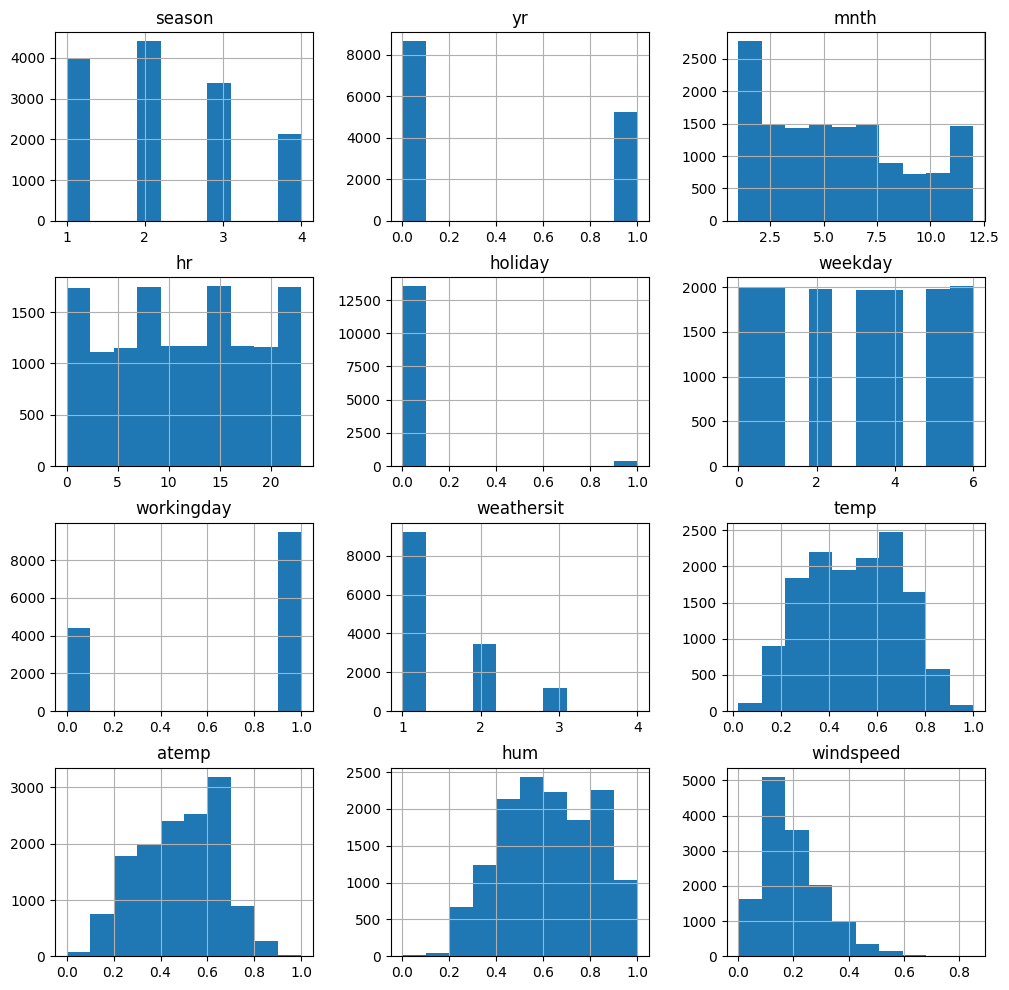

In [10]:
X_train.hist(figsize=(12,12))
plt.show()


In [11]:
X_train.select_dtypes(include='number').corrwith(y_train['cnt']).sort_values(ascending=False)

,0
temp,0.430873
atemp,0.426524
hr,0.400389
yr,0.236901
season,0.122029
windspeed,0.101384
mnth,0.084255
workingday,0.021173
weekday,0.016973
holiday,-0.024599


In [12]:
X_train_final = X_train.drop(columns=['dteday'])
X_test_final = X_test.drop(columns=['dteday'])

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, SGDRegressor

dummy_reg = DummyRegressor()
forest_reg = RandomForestRegressor(random_state=42)
lin_reg = LinearRegression()
sgd_reg = SGDRegressor(random_state=42)
sgd_no_fit = SGDRegressor(random_state=42, fit_intercept=False)

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sgd_pip = Pipeline([
    ('standard', StandardScaler()),
    ('sgd', SGDRegressor(random_state=42))
])

In [15]:
timecv = TimeSeriesSplit(n_splits=5)

In [16]:
score = cross_val_score(dummy_reg, X_train_final, y_train, cv=timecv,
                        scoring="neg_mean_absolute_error")
# "neg_root_mean_squared_error"
# "neg_mean_absolute_error"


In [17]:
mae_score = -score
print(f'{mae_score.mean():.2f}')
print(f'{mae_score.std():.2f}')

138.08
30.75


In [18]:
forest_score = cross_val_score(forest_reg, X_train_final, y_train['cnt'], cv=timecv,
                               scoring='neg_mean_absolute_error')

In [19]:
lin_score = -cross_val_score(lin_reg, X_train_final, y_train, cv=timecv,
                           scoring='neg_mean_absolute_error')

In [20]:
sgd_score = -cross_val_score(sgd_pip, X_train_final, y_train['cnt'], cv=timecv,
                             scoring='neg_mean_absolute_error')

In [21]:
sgd_score_nofit = -cross_val_score(sgd_no_fit, X_train_final, y_train['cnt'], cv=timecv,
                                   scoring='neg_mean_absolute_error')

In [22]:
frt_mae = -forest_score
print('Based Model using MAE')
print(f'Mean error: {mae_score.mean():.2f}')
print(f'Std error: {mae_score.std():.2f}')

print('\nRandom Forest using MAE')
print(f'Mean error: {frt_mae.mean():.2f}')
print(f'Std error: {frt_mae.std():.2f}')

Based Model using MAE
Mean error: 138.08
Std error: 30.75

Random Forest using MAE
Mean error: 52.29
Std error: 13.76


In [23]:
print(f'Mean error: {lin_score.mean():.2f}')
print(f'Std error: {lin_score.std():.2f}')

Mean error: 109.15
Std error: 23.26


In [24]:
print(f'Mean error: {sgd_score.mean():.2f}')
print(f'Std error: {sgd_score.std():.2f}')

Mean error: 108.25
Std error: 23.12


In [25]:
print(f'Mean error: {sgd_score_nofit.mean():.2f}')
print(f'Std error: {sgd_score_nofit.std():.2f}')

Mean error: 112.51
Std error: 21.33


In [26]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

model_final = forest_reg.fit(X_train_final, y_train['cnt'])

y_pred = model_final.predict(X_test_final)


In [ ]:
mae_frt = mean_absolute_error(y_test, y_pred)
root_frt = root_mean_squared_error(y_test, y_pred)
print(f'MAE: {mae_frt:.2f}')
print(f'RMSE: {root_frt:.2f}')

MAE: 44.99
RMSE: 69.56


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1650: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


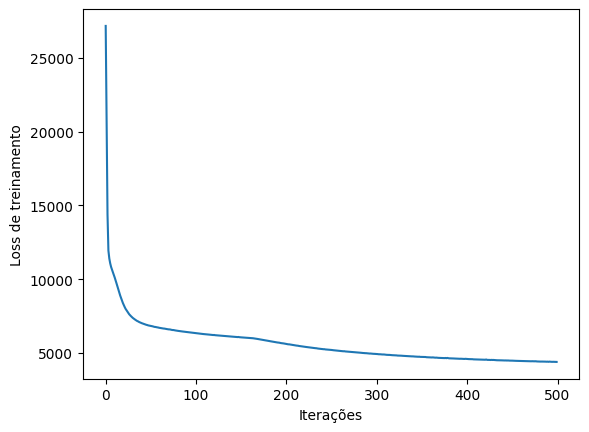

In [27]:
from sklearn.neural_network import MLPRegressor
import matplotlib.pyplot as plt

model = MLPRegressor(
    solver="adam",
    max_iter=500,
    random_state=42
)

model.fit(X_train_final, y_train)

plt.plot(model.loss_curve_)
plt.xlabel("Iterações")
plt.ylabel("Loss de treinamento")
plt.show()

In [31]:
result = model.predict(X_test_final)

In [33]:
mae_model = mean_absolute_error(y_test, result)
mae_model

93.2688953942269

####Objetivo do projeto:
- Prever quantas bicicletas seriam alugadas por hora em determinado período do dia, dado as circunstancai do clima e ambiente.
- Foi usado um modelo de regressão, dado ao objetivo de valores da quantitade de bike que seria alugado.

####Dados utilizados:
- Foi usado como target, a feature 'cnt', a qual mostra-se quantas bikes foram alugadas em uma hora.
- Os dados de treino, foi retirado a feature 'dteday', visto que as features 'hr, mnth e yr' seriam praticamente informações destrinchadas da feature 'dteday'

####Metodologia:

- Primeiro foi conferido o conteúdo interno dos dados para entender como se encontrava a organização dos dados. Foi concluído que as amostras se encontram organizadas por período de janeiro até dezembro, de 2011 e de 2012. Logo não foi preciso usar técnica para organizar as amostras em sequencia temporal.
- No train_test_split, o hiperparametro é 'shuffle=False', porque deve-se seguir o período temporal; test_size=0.2 para validação dos dados, onde 20% dos dados era do período de novembro e dezembro, equanto em X_train era do período janeiro a outubro.
- Utilizou-se EDA, com histograma do X_train com objetivo de procurar alguma correlação entre as features em relação o target.
- Teve como referência, o "dummy_regressor" como model based; Estimadores que foram usados: RandomForestRegressor, SGDRegressor, LinearRegressor

####Resultados: quais métricas foram obtidas e qual modelo foi escolhido?
- TimeSeriesSplit foi utilizado com intuito de usá-lo no "cross_val_score" para que seguisse a ordem temporal dos dados.
- Dado a perfomance do RandomForest comparado ao model based e os outros algoritmos ao usar "cross_val_score", teve uma menor loss, com o erro médio de "52.29" em relação do dummy_regressor(erro médio de 138.08).
- Ao fazer a predição em "X_test" usando como métricas MAE e RMSE, resultou-se em "MAE: 44.99, RMSE: 69.56"


####Conclusão e limitações:
- Como o limite de tolerância de erro estipulado pelo contratante o serviço era de 60, foi resolvido o devido problema.
- Para uma melhora do modelo, deve-se procurar mais correlações entre as featues e testar outros estimadores, assim como testar outros hiperparâmetros para uma menor loss da tarefa requisitada.